# Evaluation gap: how much do the scores depend on recent sales?

All the results so far train on every sale that closed before the evaluation month. That matches a model that values a home **at today's market**: in March, it has seen sales through February.

If the model instead predicts a home's close price **before it is listed**, it is used in the listing month. A typical sale closes about 2 months after listing, so at prediction time the model would only have seen sales up to about 2 months before the close. The sales in between are a recent read on prices that it wouldn't have.

This notebook measures how much that matters, for the baseline and for the best model from `05_feature_engineering.ipynb`, using only the validation months (the test month 2026-04 is held out):
1. **Fixed gap:** train on the 18 months ending 0, 1, 2 or 3 months before each validation month.
2. **Exact cutoff:** for each sale in the last validation month (2026-03), train only on sales that closed before that home's own listing month.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from idx_exchange_data_science import cleaning as cl
from idx_exchange_data_science import features as ft
from idx_exchange_data_science.modeling import backtest, build_model, fit_window, linear_baseline, random_forest, score
from idx_exchange_data_science.paths import ARCHIVE_DIR
from idx_exchange_data_science.preprocessing import make_preprocessor
from idx_exchange_data_science.splits import split, validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834"]

X = 18
GAPS = [0, 1, 2, 3]
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month

df = ft.build_table()
MODELS = {
    "Baseline (LR, Dataset A)": linear_baseline(),
    "Random Forest + school districts": build_model(
        random_forest(), make_preprocessor(ft.DISTRICT_NUMERIC_COLS, ft.DISTRICT_COLS)),
}

## 1. How long from listing to close?
`ListingContractDate` isn't in Dataset A, so `ft.build_table()` reads it back from the filtered file and adds `MonthsToClose`. Gaps over 24 months are treated as unknown (most likely relisted homes with a stale date).

In [2]:
in_validation = df[cl.DATE_COL].dt.to_period("M").isin(EVAL_MONTHS)
months_to_close = df["MonthsToClose"].clip(upper=6)
shares = pd.DataFrame({
    "all sales": months_to_close.value_counts(normalize=True, dropna=False),
    "validation months": months_to_close[in_validation].value_counts(normalize=True, dropna=False),
}).sort_index()
shares.index = [("6+" if m == 6 else "unknown" if pd.isna(m) else str(int(m))) for m in shares.index]
shares.rename_axis("months from listing to close")

,all sales,validation months
months from listing to close,,
0,0.0410,0.0397
1,0.3337,0.2851
2,0.2891,0.2717
3,0.1423,0.1465
4,0.0756,0.0928
5,0.0450,0.0616
6+,0.0728,0.1020
unknown,0.0005,0.0006


**Observations**
- **Most homes close 1–3 months after listing.** The median is 2 months, and only about 4% close in the month they list. About 7% take 6 months or more (10% in the validation months).
- **The listing date is almost always known** (all but 0.05% of sales).

## 2. Fixed gap
The training window stays 18 months long and just ends earlier, so the only thing that changes is how recent the training sales are. Scores are means over the same 6 validation months as before (2025-10 to 2026-03).

In [3]:
rows = []
for gap in GAPS:
    scores, _ = backtest(MODELS, df, EVAL_MONTHS, X, gap=gap)
    rows.append(scores.assign(gap=gap))
fixed_gap = pd.concat(rows).groupby(["model", "gap"], sort=False)[["r2", "mae", "mape"]].mean().reset_index()
fixed_gap["r2_vs_gap_0"] = fixed_gap["r2"] - fixed_gap.groupby("model")["r2"].transform("first")
fixed_gap

,model,gap,r2,mae,mape,r2_vs_gap_0
0,"Baseline (LR, Dataset A)",0,0.8007,"207,042.7974",0.1609,0.0000
1,Random Forest + school districts,0,0.8923,"151,207.2719",0.1196,0.0000
2,"Baseline (LR, Dataset A)",1,0.8000,"207,261.7395",0.1612,-0.0008
3,Random Forest + school districts,1,0.8924,"151,325.8270",0.1201,0.0000
4,"Baseline (LR, Dataset A)",2,0.7997,"207,399.2504",0.1615,-0.0011
5,Random Forest + school districts,2,0.8913,"152,117.9551",0.1207,-0.0010
6,"Baseline (LR, Dataset A)",3,0.8000,"207,475.5655",0.1617,-0.0007
7,Random Forest + school districts,3,0.8907,"152,526.9837",0.1211,-0.0016


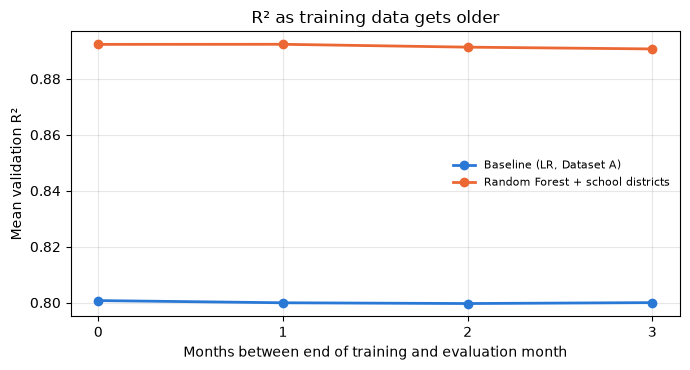

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for color, (name, group) in zip(COLORS, fixed_gap.groupby("model", sort=False)):
    ax.plot(group["gap"], group["r2"], marker="o", markersize=6, linewidth=2, color=color, label=name)
ax.set(xlabel="Months between end of training and evaluation month", ylabel="Mean validation R²", xticks=GAPS,
       title="R² as training data gets older")
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

**Observations**
- **Older training data barely hurts either model.** Ending training 2 months early costs the forest 0.001 R² and about \$900 of MAE, and the baseline 0.001 R² and about \$400. Even 3 months early costs the forest only 0.0016.
- **Prices hardly moved over this period,** so the newest sales don't tell the model much that the 18-month window doesn't. In a fast-moving market this gap would matter more, and it should be re-checked if the data is extended.

## 3. Exact cutoff on the last validation month
Each 2026-03 sale is predicted by a model trained on the 18 months before its own listing month. This is the honest pre-listing score. Sales listed 6 or more months before close use a 6-month gap, and sales with an unknown listing date use the median (2). The evaluated rows are the same as in the gap-0 run, so the scores can be compared directly.

In [5]:
month = EVAL_MONTHS[-1]
_, evaluation = split(df, month, X)
eval_gap = evaluation["MonthsToClose"].fillna(evaluation["MonthsToClose"].median()).clip(upper=6).astype(int)

current, exact = {}, {}
for name, model in MODELS.items():
    preds = {gap: pd.Series(fit_window(model, df, month, X, gap=gap).predict(evaluation), index=evaluation.index)
             for gap in sorted(eval_gap.unique())}
    current[name] = preds[0]
    exact[name] = pd.Series([preds[g][i] for i, g in eval_gap.items()], index=evaluation.index)

exact_scores = pd.DataFrame(
    [{"model": name, "cutoff": "before the evaluation month (current)", **score(evaluation[cl.TARGET], current[name])}
     for name in current]
    + [{"model": name, "cutoff": "before each home's listing month", **score(evaluation[cl.TARGET], exact[name])}
       for name in exact]
)
exact_scores

,model,cutoff,r2,mae,mape,median_ape,within_10pct
0,"Baseline (LR, Dataset A)",before the evaluation month (current),0.7967,"210,881.5409",0.1583,0.1204,0.4291
1,Random Forest + school districts,before the evaluation month (current),0.8953,"151,798.7079",0.1149,0.0758,0.6034
2,"Baseline (LR, Dataset A)",before each home's listing month,0.7964,"211,738.8299",0.1590,0.1206,0.4293
3,Random Forest + school districts,before each home's listing month,0.8945,"153,407.4158",0.1168,0.0762,0.6015


In [6]:
by_gap = pd.DataFrame({
    "sales": eval_gap.value_counts().sort_index(),
    **{f"{name} R²": evaluation.groupby(eval_gap).apply(lambda g: score(g[cl.TARGET], exact[name][g.index])["r2"])
       for name in exact},
})
by_gap.rename_axis("months from listing to close")

,sales,"Baseline (LR, Dataset A) R²",Random Forest + school districts R²
months from listing to close,,,
0,585,0.7797,0.8698
1,3596,0.8181,0.9059
2,3613,0.8204,0.9040
3,1010,0.8296,0.9116
4,742,0.6184,0.8925
5,707,0.7913,0.8834
6,1151,0.7477,0.8350


**Observations**
- **The honest pre-listing score is essentially the same.** On 2026-03 the forest goes from R² 0.8953 to 0.8945, MAE from \$151.8K to \$153.4K and mean % error from 11.5% to 11.7%. The baseline moves by less than 0.001.
- **R² by months to close mostly reflects which homes take longer to sell, not how old the training data is.** Homes that sell within the month (0) or take 6+ months are harder to price, and they score lower for both models.

## Summary
- **Positioning the model as a pre-listing prediction costs almost nothing.** With training cut off at each home's listing month, the best model (Random Forest + school districts) scores R² 0.894 on 2026-03, MAE \$153K, against 0.895 / \$152K for the standard split.
- **The standard split (train on everything before the evaluation month) is fine to keep for comparing models.** The difference is about 0.001 R² for this period.
- **Features still have to be known at the listing month.** Anything that describes the market, such as listing supply, must be lagged from the listing date, not the close date.

In [7]:
fixed_gap.to_csv(ARCHIVE_DIR / "evaluation_gap.csv", index=False)
exact_scores.to_csv(ARCHIVE_DIR / "evaluation_gap_exact.csv", index=False)